# KNN, Naive Bayes & Decision Trees (+ new classification metrics)
### Predicting whether an app user will subscribe to premium

**Datasets (provided separately):**
- `app_users.csv` - 8000 users: `sessions_per_week`, `avg_session_minutes`, `features_used`, `days_since_install`, plus TWO targets: `subscribed` (0/1, for classification) and `monthly_spend_rs` (a number, for regression).
- `sms_messages.csv` - 6000 text messages labelled `label` = 1 (spam) or 0 (normal). Used for Naive Bayes on text.

**What this notebook covers (theory in markdown, then code below it):**
1. A clearer look at the confusion matrix, plus new metrics: **accuracy, specificity, ROC curve and AUC**
2. **K-Nearest Neighbours** - classifier and regressor, distance metrics, weighting, choosing k
3. **Naive Bayes** - Bayes' theorem, the independence assumption, Gaussian / Multinomial / Bernoulli
4. **Decision Trees** - splitting, entropy, information gain, Gini, leaves, pruning, hyperparameters, visualization

Two code cells contain a small deliberate bug marked `# FIX ME`, with a hint. Find and fix them - the results look wrong until you do.

In [1]:
import os
data_paths = {}
for base in ['/kaggle/input', '.']:            # Kaggle first, then the current folder (for running locally)
    if os.path.exists(base):
        for dirname, _, filenames in os.walk(base):
            for filename in filenames:
                if 'app_users' in filename and filename.endswith('.csv'):
                    data_paths['app'] = os.path.join(dirname, filename)
                if 'sms_messages' in filename and filename.endswith('.csv'):
                    data_paths['sms'] = os.path.join(dirname, filename)
print(data_paths)
# If this prints an empty dict: click 'Add Input' and attach BOTH csv files first

{'app': '/kaggle/input/datasets/gangabhavanidasam/knn-dataset/app_users.csv', 'sms': '/kaggle/input/datasets/gangabhavanidasam/knn-dataset/sms_messages.csv'}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, roc_curve, roc_auc_score,
                             mean_absolute_error, mean_squared_error, r2_score)

sns.set_style('whitegrid')

---
# Part 1 - Load the data and split it

## Theory
Same routine as always: look at the data, check for missing values, then split into a **training set** (the model learns from it) and a **test set** (hidden from the model, used only for an honest final check).

We will also **scale** the features (mean 0, spread 1). Why? Some models (KNN especially) work by measuring distances, and a feature measured in big numbers (like `days_since_install`, up to 365) would completely drown out a feature measured in small numbers (like `features_used`, up to 12). Scaling gives every feature a fair voice. Decision trees do NOT need scaling - they only ask yes/no questions about one feature at a time.

In [3]:
assert 'app' in data_paths, "Attach app_users.csv via Add Input first."
df = pd.read_csv(data_paths['app'])
df.head()

,sessions_per_week,avg_session_minutes,features_used,days_since_install,subscribed,monthly_spend_rs
0,8,32.2,7,53,1,264.0
1,7,19.6,8,363,0,158.0
2,12,18.5,8,292,1,256.0
3,9,8.4,5,36,0,134.0
4,1,33.2,3,12,0,69.0


In [4]:
print(df.isnull().sum())
print()
print('Subscription rate:', round(df['subscribed'].mean(), 3))
df.describe().round(1)

sessions_per_week      0
avg_session_minutes    0
features_used          0
days_since_install     0
subscribed             0
monthly_spend_rs       0
dtype: int64

Subscription rate: 0.329


,sessions_per_week,avg_session_minutes,features_used,days_since_install,subscribed,monthly_spend_rs
count,8000.0,8000.0,8000.0,8000.0,8000.0,8000.0
mean,8.5,20.0,6.0,181.9,0.3,156.9
std,2.9,12.7,2.2,105.1,0.5,72.9
min,1.0,2.0,1.0,1.0,0.0,0.0
25%,6.0,10.7,4.0,90.0,0.0,101.0
50%,8.0,17.4,6.0,184.0,0.0,129.0
75%,10.0,26.4,7.0,272.0,1.0,231.0
max,22.0,90.0,12.0,365.0,1.0,362.0


In [5]:
feature_cols = ['sessions_per_week', 'avg_session_minutes', 'features_used', 'days_since_install']
X = df[feature_cols].values
y = df['subscribed'].values
y_spend = df['monthly_spend_rs'].values      # the regression target, used later

X_train, X_test, y_train, y_test, ys_train, ys_test = train_test_split(
    X, y, y_spend, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn mean/std from TRAINING data only
X_test_scaled = scaler.transform(X_test)          # apply the same numbers to test data (never refit on test)

print('Train:', X_train.shape[0], '| Test:', X_test.shape[0])

Train: 6400 | Test: 1600


---
# Part 2 - Classification metrics, a clearer look

## 2.1 The confusion matrix, slowly

Every classifier makes predictions, and every prediction is either right or wrong. A confusion matrix simply COUNTS the four possible situations.

First decide what "positive" means. **Positive = the thing we are trying to detect.** In our app problem, positive = "the user subscribes".

| | Actually subscribed | Actually did NOT subscribe |
|---|---|---|
| **Model said: will subscribe** | **True Positive (TP)** - said yes, and it was yes | **False Positive (FP)** - said yes, but it was no |
| **Model said: will not subscribe** | **False Negative (FN)** - said no, but it was yes | **True Negative (TN)** - said no, and it was no |

**The trick to never mix up the names:**
- The **2nd word** (Positive/Negative) is what the MODEL SAID.
- The **1st word** (True/False) tells you whether the model was RIGHT.

So "False Positive" = the model said Positive, and that was wrong. "False Negative" = the model said Negative, and that was wrong.

**Analogy - an invigilator in an exam hall:** the invigilator's job is to catch cheaters (positive = "cheater").
- **TP:** flagged a student, and they really were cheating. Caught!
- **FP:** flagged a student, but they were honest. A false accusation.
- **FN:** did not flag a student who WAS cheating. Missed!
- **TN:** did not flag an honest student. Correct pass.

**Which mistake is worse?** It depends on the job. For the invigilator, a false accusation (FP) wrongly punishes an honest student; a miss (FN) lets cheating slide. For our app, an FP means we offer a premium discount to someone who would never subscribe (wasted money); an FN means we ignore someone who would have subscribed (lost revenue).

## 2.2 The metrics built from those four numbers

Yesterday we met **precision, recall and F1**. Today we add **accuracy, specificity, and the ROC curve with AUC**.

| Metric | Formula | Plain-English question it answers | Analogy (invigilator) |
|---|---|---|---|
| **Accuracy** (NEW) | (TP + TN) / everyone | How often was the model right overall? | Out of all students, how often was the call correct? |
| **Precision** | TP / (TP + FP) | Of those flagged positive, how many truly were? | Of everyone flagged, how many really cheated? |
| **Recall** | TP / (TP + FN) | Of all real positives, how many did we catch? | Of all real cheaters, how many did we catch? |
| **Specificity** (NEW) | TN / (TN + FP) | Of all real negatives, how many did we correctly leave alone? | Of all honest students, how many did we leave alone? |
| **F1** | 2 x P x R / (P + R) | One score balancing precision and recall | Penalises being good at only one of the two |

Recall and specificity are mirror images: recall measures how well we handle the REAL POSITIVES, specificity measures how well we handle the REAL NEGATIVES.

## 2.3 The accuracy trap
Accuracy sounds like the only number you need - but it can lie. Only about a third of users subscribe, so a lazy model that ALWAYS says "will not subscribe" is right about two-thirds of the time, while catching zero subscribers. High accuracy, completely useless model. That is why we always look at recall, precision and specificity next to accuracy.

**Analogy:** a weather forecaster in a desert who always predicts "no rain" is right 95% of the time - and has never once warned anyone about the rare rainy day.

## 2.4 ROC curve and AUC (NEW)
Yesterday we learned the **threshold**: a model outputs a probability, and we choose the cut-off (default 0.5) above which we say "positive". Change the threshold and TPR (recall) and FPR (false alarm rate) both move.

- **TPR (True Positive Rate)** = recall = TP / (TP + FN)
- **FPR (False Positive Rate)** = FP / (FP + TN) = 1 - specificity

The **ROC curve** plots TPR against FPR for EVERY possible threshold, so you see the model's performance at all strictness levels at once. **AUC** is the area under that curve:

| AUC | Meaning |
|---|---|
| 1.0 | Perfect separation of the two classes |
| 0.5 | No better than a coin flip (the diagonal line) |
| below 0.5 | Worse than random - usually a flipped label |

**A neat way to read AUC:** pick one random positive user and one random negative user. AUC is the chance that the model gives the positive one the higher probability. AUC = 0.85 means 85% of the time the model ranks them correctly.

**Analogy:** think of the invigilator's strictness dial. Very strict: catches nearly all cheaters but accuses many honest students. Very relaxed: accuses almost nobody but misses cheaters. The ROC curve records what happens at every setting of that dial.

## Implementation - a metrics toolkit we will reuse for every model today

In [6]:
def evaluate(name, y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    result = {
        'model': name,
        'accuracy': (tp + tn) / (tp + tn + fp + fn),
        'precision': tp / (tp + fp) if (tp + fp) else 0.0,
        'recall': tp / (tp + fn) if (tp + fn) else 0.0,
        'specificity': tn / (tn + fp) if (tn + fp) else 0.0,
    }
    p, r = result['precision'], result['recall']
    result['f1'] = 2 * p * r / (p + r) if (p + r) else 0.0
    if y_prob is not None:
        result['auc'] = roc_auc_score(y_true, y_prob)
    return result

def show_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['not subscribed', 'subscribed']).plot(cmap='Blues')
    plt.title(title)
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f'TP={tp} (said yes, was yes)   FP={fp} (said yes, was no)')
    print(f'FN={fn} (said no, was yes)    TN={tn} (said no, was no)')

In [7]:
# The accuracy trap in action: a lazy model that ALWAYS predicts "will not subscribe"
lazy_pred = np.zeros_like(y_test)
lazy = evaluate('lazy (always no)', y_test, lazy_pred)
pd.DataFrame([lazy]).round(3)

,model,accuracy,precision,recall,specificity,f1
0,lazy (always no),0.671,0.0,0.0,1.0,0.0


Look at the row above: **accuracy is around two-thirds, but recall is 0.** The lazy model looks decent on accuracy and catches not a single real subscriber. Any model we build today must be judged against this baseline, and by more than accuracy alone.

---
# Part 3 - K-Nearest Neighbours (KNN)

## 3.1 The idea
> "To predict something about a new point, look at the k points most similar to it, and let them decide."

**Analogy - moving to a new neighbourhood:** you want to guess whether you'll like the local biryani place. You ask the 5 people living closest to you. If 4 of 5 love it, you predict you'll love it too. KNN does exactly this with data points.

**KNN is a "lazy learner":** it does NOT study during training. `.fit()` just stores the data. All the work happens at prediction time, when it measures distances to every stored point. Think of an open-book exam: no memorising beforehand, you look things up when the question arrives.

## 3.2 Step by step
1. Take the new point.
2. Measure its distance to every training point.
3. Pick the **k** closest ones.
4. **Classification:** majority vote among those k. **Regression:** the AVERAGE of those k points' values.

(See the diagram: with k = 3, two coral neighbours beat one teal neighbour, so the new point is predicted coral.)

## 3.3 Distance metrics - how do we measure "close"?
For two points `a` and `b` with several features:

```
Euclidean distance  = sqrt( (a1-b1)^2 + (a2-b2)^2 + ... )     (straight line, "as the crow flies")
Manhattan distance  = |a1-b1| + |a2-b2| + ...                  (walking along a city grid)
Minkowski distance  = (sum of |ai-bi|^p)^(1/p)                 (general form: p=2 is Euclidean, p=1 is Manhattan)
```
**Analogy:** Euclidean is a bird flying straight to the destination. Manhattan is a taxi that must follow the street grid, so it adds up the horizontal and vertical blocks. sklearn's default is Minkowski with p=2, i.e. Euclidean.

**Scaling matters enormously here.** If one feature is in the hundreds (days since install) and another is in single digits (features used), the big one dominates every distance - like judging how similar two people are using salary in rupees and height in metres: salary wins every time. Always scale before KNN.

## 3.4 Weighting - do all k neighbours get an equal vote?
- `weights='uniform'` - every neighbour gets one equal vote.
- `weights='distance'` - closer neighbours count MORE (weight = 1 / distance).

**Analogy:** asking 5 neighbours for advice, but trusting the one next door more than the one at the end of the street.

## 3.5 Choosing k - the key hyperparameter
- **Small k (e.g. 1):** the prediction follows the single nearest point, noise and all. Jumpy, memorises the training data - **overfitting**. (Like copying one friend's quirky taste.)
- **Large k (e.g. 500):** averaging over a huge crowd, so everything drifts toward the overall majority - too blunt, **underfitting**. (Like asking the whole city.)
- **A middle value** balances the two. We find it by trying many k and watching test accuracy - that is exactly the practice task.

## Implementation 1 - KNN from scratch, for ONE new user

In [8]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))          # straight-line distance

def manhattan(a, b):
    return np.sum(np.abs(a - b))                    # city-block distance

new_user = X_test_scaled[0]                         # pretend this user just arrived
k = 5

# Step 2: distance from the new user to EVERY training user
distances = np.array([euclidean(new_user, row) for row in X_train_scaled])

# Step 3: indices of the k closest
nearest_idx = np.argsort(distances)[:k]
nearest_labels = y_train[nearest_idx]

# Step 4: majority vote
vote = np.bincount(nearest_labels).argmax()

print('Distances to the 5 nearest users:', np.round(distances[nearest_idx], 3))
print('Their labels (1 = subscribed):   ', nearest_labels)
print('Majority vote prediction:        ', vote, '| Actual:', y_test[0])
print()
print('Euclidean vs Manhattan between two users:',
      round(euclidean(X_test_scaled[0], X_test_scaled[1]), 3), 'vs',
      round(manhattan(X_test_scaled[0], X_test_scaled[1]), 3))

Distances to the 5 nearest users: [0.085 0.157 0.172 0.192 0.239]
Their labels (1 = subscribed):    [0 0 0 0 0]
Majority vote prediction:         0 | Actual: 0

Euclidean vs Manhattan between two users: 1.308 vs 2.267


## Implementation 2 - KNN classifier with scikit-learn

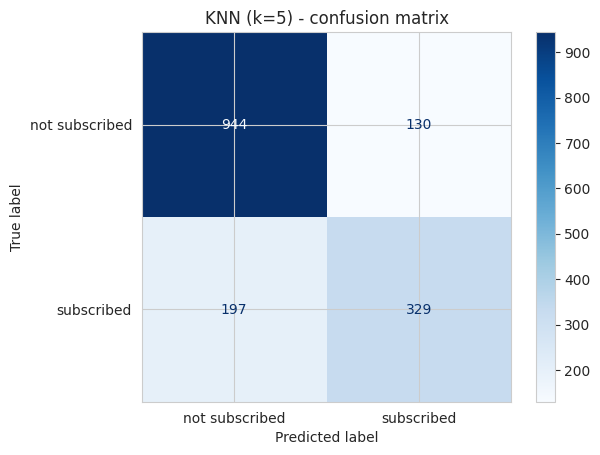

TP=329 (said yes, was yes)   FP=130 (said yes, was no)
FN=197 (said no, was yes)    TN=944 (said no, was no)


,model,accuracy,precision,recall,specificity,f1,auc
0,KNN k=5,0.796,0.717,0.625,0.879,0.668,0.842


In [9]:
# FIX ME: KNN measures distances, so it needs SCALED features, but these two lines currently hand
# it the raw, unscaled ones (days_since_install will drown out everything else).
# Hint: scaled versions of both already exist from Part 1.
X_knn_train, X_knn_test = X_train_scaled, X_test_scaled  #X_knn_train, X_knn_test = X_train, X_test

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_knn_train, y_train)                         # "fit" just stores the data - KNN is lazy

knn_pred = knn.predict(X_knn_test)
knn_prob = knn.predict_proba(X_knn_test)[:, 1]        # fraction of the k neighbours that voted "subscribed"

show_confusion(y_test, knn_pred, 'KNN (k=5) - confusion matrix')
pd.DataFrame([evaluate('KNN k=5', y_test, knn_pred, knn_prob)]).round(3)

## Practice - vary k and watch accuracy
Training accuracy vs test accuracy for k = 1 to 40. Watch for the signature of overfitting at small k (training accuracy much higher than test accuracy).

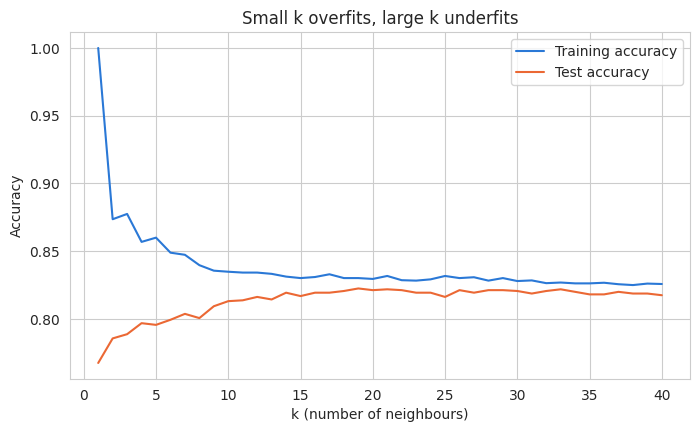

k with the best test accuracy: 19 -> 0.823


In [10]:
ks = list(range(1, 41))
train_accs, test_accs = [], []
for k in ks:
    model = KNeighborsClassifier(n_neighbors=k).fit(X_knn_train, y_train)
    train_accs.append(model.score(X_knn_train, y_train))
    test_accs.append(model.score(X_knn_test, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(ks, train_accs, label='Training accuracy', color='#2a78d6')
plt.plot(ks, test_accs, label='Test accuracy', color='#eb6834')
plt.xlabel('k (number of neighbours)')
plt.ylabel('Accuracy')
plt.title('Small k overfits, large k underfits')
plt.legend()
plt.show()

best_k = ks[int(np.argmax(test_accs))]
print('k with the best test accuracy:', best_k, '->', round(max(test_accs), 3))

## Distance metric and weighting comparison

In [11]:
rows = []
for metric in ['euclidean', 'manhattan']:
    for weights in ['uniform', 'distance']:
        m = KNeighborsClassifier(n_neighbors=best_k, metric=metric, weights=weights).fit(X_knn_train, y_train)
        rows.append({'metric': metric, 'weights': weights, 'test_accuracy': round(m.score(X_knn_test, y_test), 4)})
pd.DataFrame(rows)

,metric,weights,test_accuracy
0,euclidean,uniform,0.8225
1,euclidean,distance,0.8150
2,manhattan,uniform,0.8213
3,manhattan,distance,0.8144


## 3.6 KNN as a REGRESSOR
Same idea, but instead of a vote, take the **average** of the k neighbours' values. **Analogy:** estimating the rent of a flat by averaging the rents of the 5 most similar flats nearby.

Here we predict `monthly_spend_rs` (a number). Metrics are the regression ones from earlier: MAE, RMSE, R-squared.

In [12]:
knn_reg = KNeighborsRegressor(n_neighbors=10, weights='distance')
knn_reg.fit(X_train_scaled, ys_train)
spend_pred_knn = knn_reg.predict(X_test_scaled)

print(f'KNN regressor  MAE: {mean_absolute_error(ys_test, spend_pred_knn):.1f} rupees')
print(f'KNN regressor  RMSE: {np.sqrt(mean_squared_error(ys_test, spend_pred_knn)):.1f} rupees')
print(f'KNN regressor  R2: {r2_score(ys_test, spend_pred_knn):.3f}')

KNN regressor  MAE: 38.9 rupees
KNN regressor  RMSE: 50.7 rupees
KNN regressor  R2: 0.505


---
# Part 4 - Naive Bayes

## 4.1 Bayes' theorem - updating a belief with new evidence
```
P(A | B) = P(B | A) x P(A) / P(B)
```
In words: **how likely is A, now that I have seen clue B?** = (how often clue B shows up when A is true) x (how likely A was to begin with) / (how common clue B is overall).

**Analogy - a detective:** before looking at anything, the detective has a starting suspicion (the **prior**). Each clue found at the scene shifts that suspicion up or down. The updated suspicion is the **posterior**.

**Worked example - spam:** suppose 30% of all messages are spam. The word "free" appears in 60% of spam messages but only 5% of normal ones. A new message contains "free". What is the chance it is spam?

```
P(spam | free) = P(free | spam) x P(spam) / P(free)
               = 0.60 x 0.30 / (0.60 x 0.30 + 0.05 x 0.70)
               = 0.18 / (0.18 + 0.035) = 0.18 / 0.215 = about 0.84
```
One clue moved the belief from 30% to 84%.

## 4.2 Classification with several clues, and why it is called "naive"
A message has many words. For each class we compute:
```
P(class | words)  is proportional to  P(class) x P(word1 | class) x P(word2 | class) x P(word3 | class) x ...
```
and predict the class with the higher score.

**The naive (independence) assumption:** multiplying the word probabilities together assumes every word is **independent** of the others once we know the class. That is rarely true in real life ("free" and "prize" often appear together), which is exactly why it is called naive. **Analogy:** a detective who counts "muddy shoes" and "wet coat" as two separate pieces of evidence, even though both are simply caused by rain. The assumption is wrong, yet the classifier still works surprisingly well, because we only need the right class to score highest, not perfectly calibrated numbers.

**Zero-probability problem and smoothing:** if a word never appeared in spam during training, its probability is 0, and multiplying by 0 wipes out the whole product. **Laplace smoothing** (`alpha=1` in sklearn) adds one imaginary sighting of every word to every class, so nothing is ever exactly zero.

## 4.3 Three variants - choose by the type of feature

| Variant | Features it expects | Models each feature as | Typical use |
|---|---|---|---|
| **GaussianNB** | continuous numbers | a bell curve (mean and spread) per class | measurements like minutes, sessions |
| **MultinomialNB** | counts | how many times each word appears | text classification with word counts |
| **BernoulliNB** | yes/no (0 or 1) | is the word present or absent | short texts, binary features |

## 4.4 When does Naive Bayes work well?
**Text.** Thousands of word features, a reasonable amount of independence between them, very fast training, and it works even with little data. Spam filters, sentiment, topic tagging.

## Implementation 1 - GaussianNB on the numeric app data

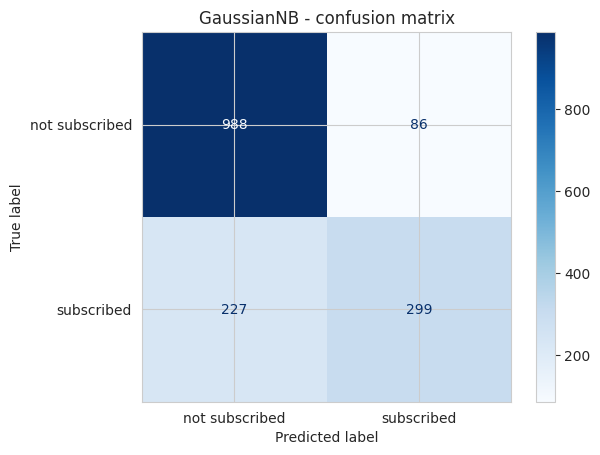

TP=299 (said yes, was yes)   FP=86 (said yes, was no)
FN=227 (said no, was yes)    TN=988 (said no, was no)


,model,accuracy,precision,recall,specificity,f1,auc
0,GaussianNB,0.804,0.777,0.568,0.92,0.656,0.878


In [13]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)                         # no scaling needed - it models each feature separately

gnb_pred = gnb.predict(X_test)
gnb_prob = gnb.predict_proba(X_test)[:, 1]

show_confusion(y_test, gnb_pred, 'GaussianNB - confusion matrix')
pd.DataFrame([evaluate('GaussianNB', y_test, gnb_pred, gnb_prob)]).round(3)

## Implementation 2 - Naive Bayes on TEXT (spam detection)
Computers cannot read words, so `CountVectorizer` turns each message into a row of word counts (a bag of words).

In [14]:
assert 'sms' in data_paths, "Attach sms_messages.csv via Add Input first."
sms = pd.read_csv(data_paths['sms'])
print(sms['label'].value_counts(normalize=True).round(3).to_dict(), '(1 = spam)')
sms.sample(5, random_state=1)

{0: 0.654, 1: 0.346} (1 = spam)


,message,label
1483,a on urgent your tonight will class home have,0
2185,please will is now class new see notes lunch c...,0
2520,notes claim prize sorry offer new library me,0
3721,for me discount deal new assignment to,0
3727,tonight win new please today your we call rewa...,1


In [15]:
txt_train, txt_test, ty_train, ty_test = train_test_split(
    sms['message'], sms['label'], test_size=0.2, random_state=42, stratify=sms['label'])

vec = CountVectorizer()
Xt_train = vec.fit_transform(txt_train)           # learn the vocabulary from TRAINING messages only
Xt_test = vec.transform(txt_test)
print('Vocabulary size:', len(vec.vocabulary_), 'words')

mnb = MultinomialNB(alpha=1.0)                    # alpha=1 is Laplace smoothing
mnb.fit(Xt_train, ty_train)
mnb_pred = mnb.predict(Xt_test)
mnb_prob = mnb.predict_proba(Xt_test)[:, 1]

print(pd.DataFrame([evaluate('MultinomialNB (counts)', ty_test, mnb_pred, mnb_prob)]).round(3).to_string(index=False))

Vocabulary size: 54 words
                 model  accuracy  precision  recall  specificity    f1   auc
MultinomialNB (counts)     0.955      0.943   0.925        0.971 0.934 0.988


In [16]:
# Bernoulli variant: only cares whether a word is PRESENT (1) or ABSENT (0)
vec_bin = CountVectorizer(binary=True)
Xb_train = vec_bin.fit_transform(txt_train)
Xb_test = vec_bin.transform(txt_test)

bnb = BernoulliNB(alpha=1.0).fit(Xb_train, ty_train)
bnb_pred = bnb.predict(Xb_test)
print(pd.DataFrame([evaluate('BernoulliNB (present/absent)', ty_test, bnb_pred, bnb.predict_proba(Xb_test)[:, 1])]).round(3).to_string(index=False))

                       model  accuracy  precision  recall  specificity    f1   auc
BernoulliNB (present/absent)     0.952      0.939   0.923        0.968 0.931 0.986


In [17]:
# Which words does the model treat as spam signals? Compare each word's log-probability in spam vs normal.
words = np.array(vec.get_feature_names_out())
spam_score = mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0]     # higher = more spam-like
print('Top spam-signal words:  ', list(words[np.argsort(spam_score)[::-1][:8]]))
print('Top normal-signal words:', list(words[np.argsort(spam_score)[:8]]))

new_msgs = ['free prize claim now', 'see you at class tomorrow', 'urgent offer click now', 'please review the notes']
probs = mnb.predict_proba(vec.transform(new_msgs))[:, 1]
for m, p in zip(new_msgs, probs):
    print(f'P(spam) = {p:.3f}  ->  {m}')

Top spam-signal words:   ['discount', 'free', 'bonus', 'win', 'lottery', 'urgent', 'claim', 'limited']
Top normal-signal words: ['reached', 'bring', 'thanks', 'exam', 'notes', 'see', 'sorry', 'lunch']
P(spam) = 0.998  ->  free prize claim now
P(spam) = 0.003  ->  see you at class tomorrow
P(spam) = 0.998  ->  urgent offer click now
P(spam) = 0.016  ->  please review the notes


---
# Part 5 - Decision Trees

## 5.1 The idea
A decision tree is a flowchart of yes/no questions. To predict, start at the top, answer each question about the data, and follow the branches until you reach an answer.

**Analogy - the game of 20 Questions (or a doctor's flowchart):** "Is it an animal? Does it fly? Is it bigger than a car?" Each question narrows things down until only one answer is left. A good player asks the questions that cut the possibilities down the most.

**Parts of a tree** (see the diagram):
- **Root node** - the first question, at the top.
- **Internal node** - any later question.
- **Branch** - the Yes / No answer leading onward.
- **Leaf node** - the end of a path, holding the final prediction. Classification: the majority class in that leaf. Regression: the **average** value of the samples in that leaf.
- **Depth** - how many questions deep the longest path goes.

## 5.2 How does the tree choose its questions? Splitting and impurity
At every node the tree tries many possible splits (e.g. `sessions_per_week <= 8`, `features_used <= 5`...) and keeps the one that makes the resulting groups as **pure** as possible. A node is **pure** when it contains only one class.

**Analogy - a bag of marbles:** a bag with only red marbles is pure (no surprise when you pull one out). A bag that is half red, half blue is as mixed as it gets. A good question separates the marbles into bags that are each closer to one colour.

We need a number for "how mixed is this node". Two standard choices, where `p` is the share of each class in the node:

```
Gini index = 1 - (p1^2 + p2^2 + ...)
Entropy    = - (p1 x log2(p1) + p2 x log2(p2) + ...)
```
Both are **0 for a pure node** and **largest for a 50/50 mix** (Gini peaks at 0.5, entropy at 1.0 for two classes - see the curve diagram).

**Information gain** = impurity BEFORE the split - the weighted-average impurity AFTER the split. It measures how much cleaner the groups became. The tree picks the split with the highest gain.

**Worked example:** a node of 10 users, 6 subscribed and 4 not.
```
Gini    = 1 - (0.6^2 + 0.4^2) = 1 - 0.52 = 0.48
Entropy = -(0.6 x log2 0.6 + 0.4 x log2 0.4) = 0.971
```
A question splits them into a left group (5 users, all subscribed) and a right group (5 users: 1 subscribed, 4 not). The left group is pure; the right group has Gini 0.32. Weighted Gini after = 0.5 x 0 + 0.5 x 0.32 = 0.16, so Gini gain = 0.48 - 0.16 = 0.32. The code below checks these numbers.

## 5.3 Entropy vs Gini - which one?
Both measure impurity and behave almost identically (see the curves). **Gini** is sklearn's default and slightly faster (no logarithm). **Entropy** is the information-theory version and can be marginally more sensitive to small differences. In practice the accuracy is usually very close; you can simply try both as a hyperparameter.

## 5.4 Overfitting and pruning
Left alone, a tree keeps asking questions until every leaf is pure - it memorises the training data, even its noise. **Analogy:** the student who memorises every practice question and answer, and falls apart when the real exam is worded differently.

**Pruning** controls this - like trimming an overgrown garden tree so it stays healthy:
- **Pre-pruning:** stop the tree from growing too far, using the hyperparameters below.
- **Post-pruning:** grow the full tree, then cut away branches that add little value (in sklearn: `ccp_alpha`, cost-complexity pruning).

## 5.5 Hyperparameters

| Hyperparameter | What it controls | Effect |
|---|---|---|
| `max_depth` | the maximum number of questions in any path | smaller = simpler tree, less overfitting |
| `min_samples_split` | a node needs at least this many samples before it may split | larger = fewer splits |
| `min_samples_leaf` | every leaf must contain at least this many samples | larger = smoother, less memorising |
| `criterion` | `'gini'` or `'entropy'` | which impurity measure picks the splits |

## Implementation 1 - impurity and information gain by hand

In [18]:
def gini(counts):
    p = np.array(counts) / np.sum(counts)
    return 1 - np.sum(p ** 2)

def entropy(counts):
    p = np.array(counts) / np.sum(counts)
    p = p[p > 0]                                    # log2(0) is undefined, so skip empty classes
    return -np.sum(p * np.log2(p))

parent = [6, 4]          # 6 subscribed, 4 not
left   = [5, 0]          # pure
right  = [1, 4]

for name, f in [('Gini', gini), ('Entropy', entropy)]:
    before = f(parent)
    after = (5/10) * f(left) + (5/10) * f(right)    # weighted by group size
    print(f'{name:8s} before={before:.3f}  after={after:.3f}  gain={before - after:.3f}')

Gini     before=0.480  after=0.160  gain=0.320
Entropy  before=0.971  after=0.361  gain=0.610


## Implementation 2 - an unrestricted tree (watch it memorise)

In [19]:
full_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print('Depth of the fully grown tree:', full_tree.get_depth())
print('Number of leaves:', full_tree.get_n_leaves())
print('Training accuracy:', round(full_tree.score(X_train, y_train), 3))
print('Test accuracy:    ', round(full_tree.score(X_test, y_test), 3))
print('\nA training score near 1.0 with a much lower test score is the signature of overfitting.')

Depth of the fully grown tree: 29
Number of leaves: 1319
Training accuracy: 1.0
Test accuracy:     0.777

A training score near 1.0 with a much lower test score is the signature of overfitting.


## Implementation 3 - a small tree we can actually read (visualization)

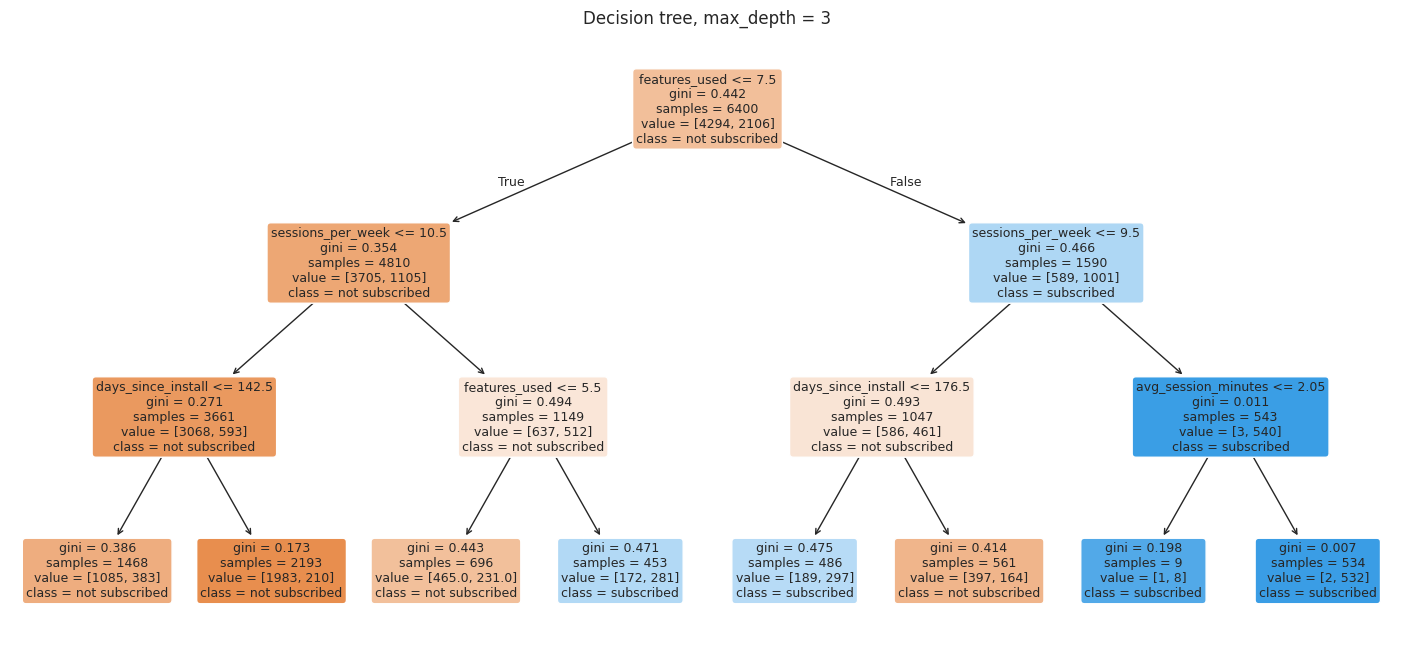

In [20]:
small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(small_tree, feature_names=feature_cols, class_names=['not subscribed', 'subscribed'],
          filled=True, rounded=True, fontsize=9)
plt.title('Decision tree, max_depth = 3')
plt.show()

In [21]:
# The same tree as plain text - easy to read top to bottom
print(export_text(small_tree, feature_names=feature_cols))

|--- features_used <= 7.50
|   |--- sessions_per_week <= 10.50
|   |   |--- days_since_install <= 142.50
|   |   |   |--- class: 0
|   |   |--- days_since_install >  142.50
|   |   |   |--- class: 0
|   |--- sessions_per_week >  10.50
|   |   |--- features_used <= 5.50
|   |   |   |--- class: 0
|   |   |--- features_used >  5.50
|   |   |   |--- class: 1
|--- features_used >  7.50
|   |--- sessions_per_week <= 9.50
|   |   |--- days_since_install <= 176.50
|   |   |   |--- class: 1
|   |   |--- days_since_install >  176.50
|   |   |   |--- class: 0
|   |--- sessions_per_week >  9.50
|   |   |--- avg_session_minutes <= 2.05
|   |   |   |--- class: 1
|   |   |--- avg_session_minutes >  2.05
|   |   |   |--- class: 1



**How to read each box in the picture:** the first line is the question; `gini` is the impurity of that node (lower = purer); `samples` is how many training users reached it; `value` is [count not subscribed, count subscribed]; `class` is the majority answer, and the colour shows which class dominates (deeper colour = purer).

## Practice - change max_depth, watch overfitting

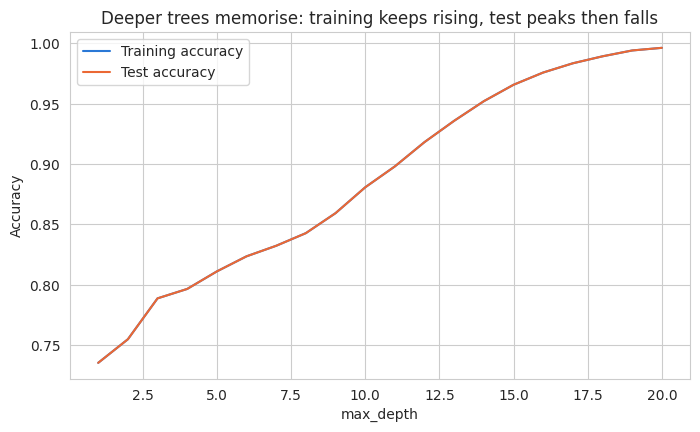

Best max_depth by test accuracy: 20


In [22]:
depths = list(range(1, 21))
train_accs, test_accs = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_accs.append(tree.score(X_train, y_train))
    # FIX ME: this line is supposed to measure TEST accuracy, but it scores the TRAINING data again.
    # Hint: if your two curves on the plot below are identical, this is why.
    test_accs.append(tree.score(X_train, y_train))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_accs, label='Training accuracy', color='#2a78d6')
plt.plot(depths, test_accs, label='Test accuracy', color='#eb6834')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Deeper trees memorise: training keeps rising, test peaks then falls')
plt.legend()
plt.show()

print('Best max_depth by test accuracy:', depths[int(np.argmax(test_accs))])

## Hyperparameters side by side, and pruning

In [23]:
configs = {
    'no limits':                        dict(),
    'max_depth=4':                      dict(max_depth=4),
    'max_depth=6, min_samples_leaf=40': dict(max_depth=6, min_samples_leaf=40),
    'max_depth=6, min_samples_split=100': dict(max_depth=6, min_samples_split=100),
    'entropy, max_depth=4':             dict(criterion='entropy', max_depth=4),
}
rows = []
for name, params in configs.items():
    t = DecisionTreeClassifier(random_state=42, **params).fit(X_train, y_train)
    rows.append({'config': name, 'leaves': t.get_n_leaves(),
                 'train_acc': round(t.score(X_train, y_train), 3),
                 'test_acc': round(t.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,config,leaves,train_acc,test_acc
0,no limits,1319,1.000,0.777
1,max_depth=4,16,0.797,0.799
2,"max_depth=6, min_samples_leaf=40",45,0.816,0.796
3,"max_depth=6, min_samples_split=100",43,0.818,0.811
4,"entropy, max_depth=4",15,0.799,0.802


In [24]:
# Post-pruning with cost-complexity pruning: a bigger ccp_alpha cuts more branches
rows = []
for a in [0, 0.0005, 0.001, 0.003, 0.01]:
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a).fit(X_train, y_train)
    rows.append({'ccp_alpha': a, 'leaves': t.get_n_leaves(),
                 'train_acc': round(t.score(X_train, y_train), 3),
                 'test_acc': round(t.score(X_test, y_test), 3)})
pd.DataFrame(rows)

,ccp_alpha,leaves,train_acc,test_acc
0,0.0000,1319,1.000,0.777
1,0.0005,56,0.829,0.812
2,0.0010,27,0.814,0.807
3,0.0030,11,0.796,0.794
4,0.0100,4,0.755,0.763


## Which features does the tree rely on?

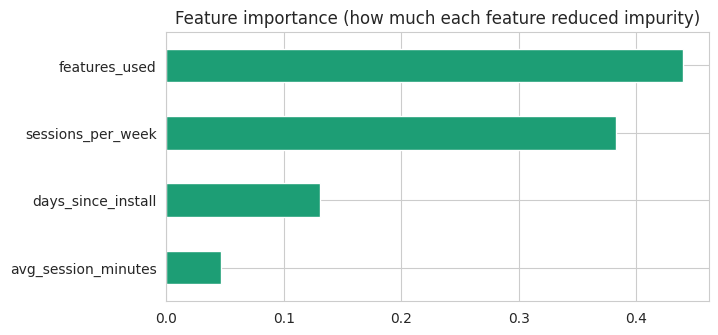

In [25]:
best_tree = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
importances = pd.Series(best_tree.feature_importances_, index=feature_cols).sort_values()

importances.plot(kind='barh', color='#1D9E75', figsize=(7, 3.5))
plt.title('Feature importance (how much each feature reduced impurity)')
plt.show()

## 5.6 Decision tree as a REGRESSOR
The tree is built the same way, with two differences: splits are chosen to reduce the **spread (variance / squared error)** of the target within each group, and each leaf predicts the **average** of its samples. The prediction curve is a staircase.

**Analogy:** pricing a used phone by asking "which model? how old? any damage?" and quoting the average sale price of past phones that landed in the same final group.

In [26]:
rows = []
for d in [2, 4, 6, 10, None]:
    reg = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, ys_train)
    rows.append({'max_depth': d,
                 'train_R2': round(reg.score(X_train, ys_train), 3),
                 'test_R2': round(reg.score(X_test, ys_test), 3),
                 'test_MAE': round(mean_absolute_error(ys_test, reg.predict(X_test)), 1)})
pd.DataFrame(rows)

,max_depth,train_R2,test_R2,test_MAE
0,2.0,0.312,0.331,47.1
1,4.0,0.428,0.425,42.6
2,6.0,0.515,0.482,39.7
3,10.0,0.687,0.397,40.8
4,NaN,1.000,0.101,49.6


Tree regressor  MAE: 41.6 rupees
Tree regressor  RMSE: 53.6 rupees
Tree regressor  R2: 0.446


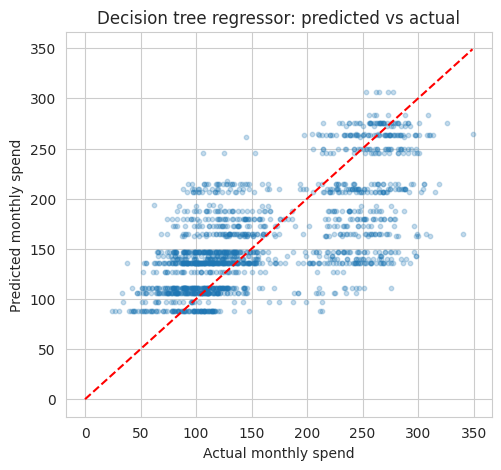

In [27]:
tree_reg = DecisionTreeRegressor(max_depth=5, random_state=42).fit(X_train, ys_train)
spend_pred_tree = tree_reg.predict(X_test)

print(f'Tree regressor  MAE: {mean_absolute_error(ys_test, spend_pred_tree):.1f} rupees')
print(f'Tree regressor  RMSE: {np.sqrt(mean_squared_error(ys_test, spend_pred_tree)):.1f} rupees')
print(f'Tree regressor  R2: {r2_score(ys_test, spend_pred_tree):.3f}')

plt.figure(figsize=(5.5, 5))
plt.scatter(ys_test, spend_pred_tree, alpha=0.25, s=10)
lims = [0, max(ys_test.max(), spend_pred_tree.max())]
plt.plot(lims, lims, color='red', linestyle='--')
plt.xlabel('Actual monthly spend')
plt.ylabel('Predicted monthly spend')
plt.title('Decision tree regressor: predicted vs actual')
plt.show()

---
# Part 6 - Comparing all the classifiers
Same test set, same metrics toolkit, plus yesterday's logistic regression as a reference point.

In [28]:
logreg = LogisticRegression().fit(X_train_scaled, y_train)

tree5 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

# NOTE: the KNN rows below use the knn built in Part 3 (with whatever X_knn_* you currently have).
models = {
    'Lazy (always no)': (lazy_pred, None),
    'Logistic Regression': (logreg.predict(X_test_scaled), logreg.predict_proba(X_test_scaled)[:, 1]),
    'KNN (k=5)': (knn_pred, knn_prob),
    'Gaussian Naive Bayes': (gnb_pred, gnb_prob),
    'Decision Tree (depth 5)': (tree5.predict(X_test), tree5.predict_proba(X_test)[:, 1]),
}
results = pd.DataFrame([evaluate(n, y_test, p, pr) for n, (p, pr) in models.items()]).set_index('model')
results.round(3)

,accuracy,precision,recall,specificity,f1,auc
model,,,,,,
Lazy (always no),0.671,0.000,0.000,1.000,0.000,NaN
Logistic Regression,0.821,0.761,0.665,0.898,0.710,0.888
KNN (k=5),0.796,0.717,0.625,0.879,0.668,0.842
Gaussian Naive Bayes,0.804,0.777,0.568,0.920,0.656,0.878
Decision Tree (depth 5),0.804,0.764,0.584,0.912,0.662,0.852


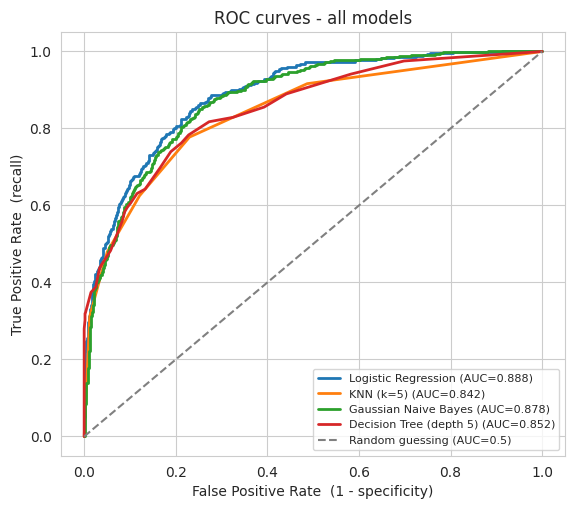

In [29]:
plt.figure(figsize=(6.5, 5.5))
for name, (pred, prob) in models.items():
    if prob is None:
        continue
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing (AUC=0.5)')
plt.xlabel('False Positive Rate  (1 - specificity)')
plt.ylabel('True Positive Rate  (recall)')
plt.title('ROC curves - all models')
plt.legend(fontsize=8)
plt.show()

## Quick guide - which model when?

| Model | Strengths | Watch out for |
|---|---|---|
| **KNN** | Simple, no training step, works for classification and regression | Slow on big data (distances to every point), needs scaling, sensitive to k |
| **Naive Bayes** | Very fast, great with text and little data, gives probabilities | Independence assumption is naive; weaker when features are strongly related |
| **Decision Tree** | Easy to read and explain, no scaling needed, handles non-linear patterns | Overfits easily if allowed to grow; unstable (small data changes can change the tree) |

*(Next class: what happens if we combine MANY trees? That is the idea behind Random Forest.)*

## Recap
- **Confusion matrix:** TP / FP / FN / TN. 2nd word = what the model said, 1st word = was it right.
- **New metrics:** accuracy (can mislead on imbalanced data), specificity (recall's mirror for negatives), ROC curve and AUC (performance at every threshold).
- **KNN:** look at the k nearest points; vote (classification) or average (regression). Needs scaling. Small k overfits, large k underfits. Distance metrics: Euclidean, Manhattan. Weighting: uniform or by distance.
- **Naive Bayes:** Bayes' theorem + the "naive" independence assumption. Gaussian for numbers, Multinomial for word counts, Bernoulli for present/absent. Shines on text.
- **Decision tree:** a flowchart of yes/no questions. Splits chosen by Gini or entropy (information gain). Leaves hold the answer. Control overfitting with pruning: max_depth, min_samples_split, min_samples_leaf, ccp_alpha.
- **Entropy vs Gini:** both measure impurity, nearly identical in practice; Gini is the faster default.

---

## Assignment
1. Fix both `# FIX ME` bugs and re-run the notebook from the top.
2. **Vary k:** on your own, try KNN with k from 1 to 60 and a different distance metric; report the best k and describe what happens to training vs test accuracy at the extremes.
3. **Change max_depth:** report the depth where test accuracy peaks, and the depth after which the tree starts to overfit.
4. In a markdown cell, explain in your own words: what is a False Positive and what is a False Negative for the app-subscription problem, and which one costs the company more?
5. Spam filters: why does Naive Bayes work well on text even though its independence assumption is wrong?
6. Compare Gini vs entropy on this dataset (use `criterion=`) and report whether the difference matters.
